# Clasificación de imágenes CIFAR-10 con una CNN — `SEMILLA = 65`

**Universidad Andina del Cusco** · Escuela Profesional de Ingeniería de Sistemas · Inteligencia Artificial
**Evaluación de la Segunda Unidad** · Código de matrícula: `021101465` · Semilla individual: **65**

## 1. Presentación y objetivo del experimento

Este notebook documenta el experimento completo: carga y exploración de CIFAR-10, visualización de muestras,
pipeline de transformaciones con aumento de datos, partición estratificada con la semilla 65, verificación del
flujo de tensores 4D `(B, C, H, W)`, construcción de la CNN, entrenamiento con `CrossEntropyLoss` + `Adam`,
y evaluación final sobre el conjunto de prueba independiente.

> Todas las funciones provienen de `src/` (`config.py`, `dataset.py`, `model.py`, `train.py`), de modo que el
> notebook y los scripts usan exactamente la misma implementación y la misma semilla.

**Cómo abrirlo:** desde la raíz del proyecto ejecute `jupyter notebook notebooks/experiment.ipynb`
(o ábralo en VS Code y seleccione el kernel del entorno `.venv`). La primera celda de código localiza la raíz
del proyecto automáticamente.

## 2. Importación de bibliotecas

In [1]:
import os, sys, json
from pathlib import Path

# Localiza la raíz del proyecto (funciona si se abre desde la raíz o desde notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

from src import config
from src.dataset import (load_cifar10, get_transforms, get_dataloaders, show_samples,
                         compute_mean_std, class_distribution, denormalize)
from src.model import CNNCifar10, count_parameters, verify_shapes, parameters_per_layer
from src.train import evaluate, plot_confusion_matrix
from src import train as train_module

%matplotlib inline
print("Raíz del proyecto:", ROOT.name)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)

Raíz del proyecto: examen-cnn-cifar10-65
PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132


## 3. Configuración de la semilla 65

`config.set_seed()` fija `random.seed(65)`, `np.random.seed(65)`, `torch.manual_seed(65)`, las semillas de CUDA
(si hay GPU) y activa los algoritmos deterministas de PyTorch. La partición usa `random_state=65` y el
`DataLoader` de entrenamiento usa un `torch.Generator` con semilla 65.

In [2]:
SEMILLA = config.SEMILLA
assert SEMILLA == 65
config.set_seed(SEMILLA)
device = config.get_device()
print(f"SEMILLA = {SEMILLA} | dispositivo = {device}")

SEMILLA = 65 | dispositivo = cpu


## 4. Carga del dataset CIFAR-10

Se usa `torchvision.datasets.CIFAR10` (dataset oficial). Si los archivos no existen en `data/`, torchvision los
descarga (~163 MB) y verifica su integridad; si ya existen, no se vuelven a descargar.

In [3]:
train_full, test_set = load_cifar10(config.DATA_DIR, download=True)
print("Clases:", train_full.classes)
print("Entrenamiento oficial:", len(train_full), "imágenes | Prueba oficial:", len(test_set), "imágenes")

Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Entrenamiento oficial: 50000 imágenes | Prueba oficial: 10000 imágenes


## 5. Exploración inicial y dimensiones de los datos

In [4]:
print("Arreglo de imágenes (train):", train_full.data.shape, train_full.data.dtype, "-> (N, H, W, C) en uint8")
print("Arreglo de imágenes (test): ", test_set.data.shape)
print("Rango de píxeles:", train_full.data.min(), "a", train_full.data.max())
print("\nDistribución de clases (train oficial):", class_distribution(train_full.targets))
print("Distribución de clases (test oficial): ", class_distribution(test_set.targets))

mean, std = compute_mean_std(train_full)
print("\nMedia RGB calculada:", np.round(mean, 4), "| usada en config:", config.CIFAR10_MEAN)
print("Desv. RGB calculada:", np.round(std, 4), "| usada en config:", config.CIFAR10_STD)

Arreglo de imágenes (train): (50000, 32, 32, 3) uint8 -> (N, H, W, C) en uint8
Arreglo de imágenes (test):  (10000, 32, 32, 3)
Rango de píxeles: 0 a 255

Distribución de clases (train oficial): {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}
Distribución de clases (test oficial):  {'airplane': 1000, 'automobile': 1000, 'bird': 1000, 'cat': 1000, 'deer': 1000, 'dog': 1000, 'frog': 1000, 'horse': 1000, 'ship': 1000, 'truck': 1000}



Media RGB calculada: [0.4914 0.4822 0.4465] | usada en config: (0.4914, 0.4822, 0.4465)
Desv. RGB calculada: [0.247  0.2435 0.2616] | usada en config: (0.247, 0.2435, 0.2616)


## 6. Visualización de imágenes con sus etiquetas reales

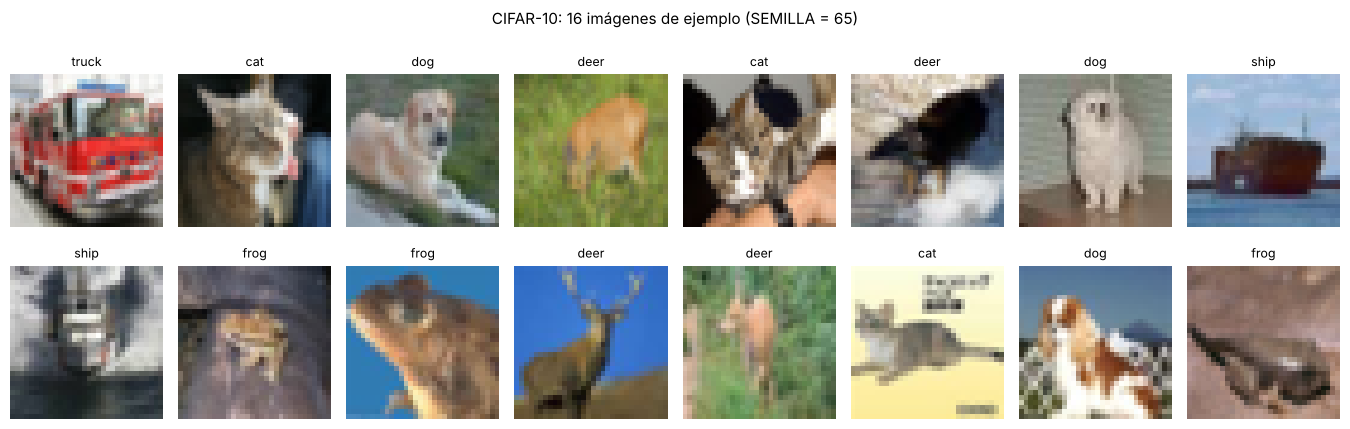

In [5]:
fig = show_samples(train_full, n=16, seed=SEMILLA, show=False)
plt.show()

## 7. Pipeline de transformaciones

| Subconjunto | Transformaciones |
|---|---|
| Entrenamiento | `RandomCrop(32, padding=4)` → `RandomHorizontalFlip(0.5)` → `ToTensor()` → `Normalize(media, desv.)` |
| Validación / Prueba | `ToTensor()` → `Normalize(media, desv.)` |

El **aumento de datos** genera, en cada época, variantes ligeramente desplazadas o reflejadas de las imágenes de
entrenamiento; así la red ve más variedad, memoriza menos y generaliza mejor. En validación y prueba **no** se
aplican transformaciones aleatorias, porque el objetivo es medir el rendimiento sobre las imágenes tal como son,
de forma determinista y comparable entre épocas.

Entrenamiento: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
) 

Evaluación: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


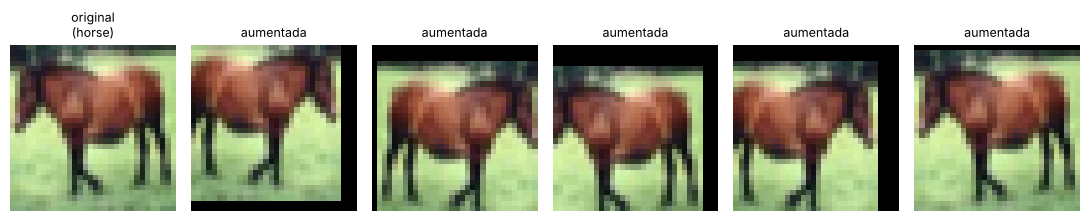

In [6]:
train_tf, eval_tf = get_transforms()
print("Entrenamiento:", train_tf, "\n\nEvaluación:", eval_tf)

# Efecto del aumento de datos sobre una misma imagen
img, label = train_full[7]
fig, axes = plt.subplots(1, 6, figsize=(11, 2.3))
axes[0].imshow(img); axes[0].set_title(f"original\n({config.CLASSES[label]})", fontsize=9)
torch.manual_seed(SEMILLA)
for ax in axes[1:]:
    ax.imshow(denormalize(train_tf(img)).permute(1, 2, 0).numpy())
    ax.set_title("aumentada", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Partición estratificada de entrenamiento y validación

El conjunto oficial de entrenamiento (50 000) se divide en **45 000 de entrenamiento** y **5 000 de validación**
con `train_test_split(..., stratify=etiquetas, random_state=65)`. El conjunto oficial de prueba (10 000) queda
apartado y solo se usa una vez, al final.

In [7]:
config.set_seed(SEMILLA)
train_loader, val_loader, test_loader, info = get_dataloaders(batch_size=config.BATCH_SIZE)

PARTICIÓN ESTRATIFICADA DE CIFAR-10   (SEMILLA = 65)
Imágenes de entrenamiento :  45000
Imágenes de validación    :   5000
Imágenes de prueba        :  10000  (conjunto oficial, separado)
Imágenes por lote (batch) :    128
--------------------------------------------------------------------------
Clase          Train       %     Val       %    Test       %
airplane        4500   10.0%     500   10.0%    1000   10.0%
automobile      4500   10.0%     500   10.0%    1000   10.0%
bird            4500   10.0%     500   10.0%    1000   10.0%
cat             4500   10.0%     500   10.0%    1000   10.0%
deer            4500   10.0%     500   10.0%    1000   10.0%
dog             4500   10.0%     500   10.0%    1000   10.0%
frog            4500   10.0%     500   10.0%    1000   10.0%
horse           4500   10.0%     500   10.0%    1000   10.0%
ship            4500   10.0%     500   10.0%    1000   10.0%
truck           4500   10.0%     500   10.0%    1000   10.0%
-------------------------------

## 9. Verificación de los tensores 4D

In [8]:
images, labels = next(iter(train_loader))
print("Lote de imágenes:", tuple(images.shape), "-> (Batch_Size, Channels, Height, Width)")
print("Lote de etiquetas:", tuple(labels.shape))
B, C, H, W = images.shape
assert (C, H, W) == (3, 32, 32)
print(f"B={B}, C={C}, H={H}, W={W} | media del lote normalizado ≈ {images.mean():.3f}, desv ≈ {images.std():.3f}")

Lote de imágenes: (128, 3, 32, 32) -> (Batch_Size, Channels, Height, Width)
Lote de etiquetas: (128,)
B=128, C=3, H=32, W=32 | media del lote normalizado ≈ -0.298, desv ≈ 1.108


## 10. Creación del modelo CNN

In [9]:
config.set_seed(SEMILLA)
model = CNNCifar10().to(device)
print(model)
print(f"\nParámetros entrenables: {count_parameters(model):,}")
for name, n in parameters_per_layer(model):
    print(f"  {name:<12}{n:>10,}")

CNNCifar10(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=

## 11. Forward pass con un lote de prueba

Se pasa un lote simulado `(8, 3, 32, 32)` y se imprimen los shapes intermedios; las aserciones de
`verify_shapes` garantizan que no existe *shape mismatch*. Luego se repite con un lote real del DataLoader.

In [10]:
_ = verify_shapes(batch_size=8, device="cpu")

model.eval()
with torch.no_grad():
    logits = model(images.to(device))
print("Lote real:", tuple(images.shape), "->", tuple(logits.shape), "(logits sin Softmax)")

VALIDACIÓN DEL FLUJO DE TENSORES 4D  (dispositivo: cpu, SEMILLA = 65)
Entrada                      -> (8, 3, 32, 32)
block1.Conv2d                -> (8, 32, 32, 32)
block1.BatchNorm2d           -> (8, 32, 32, 32)
block1.ReLU                  -> (8, 32, 32, 32)
block1.MaxPool2d             -> (8, 32, 16, 16)
block2.Conv2d                -> (8, 64, 16, 16)
block2.BatchNorm2d           -> (8, 64, 16, 16)
block2.ReLU                  -> (8, 64, 16, 16)
block2.MaxPool2d             -> (8, 64, 8, 8)
block3.Conv2d                -> (8, 128, 8, 8)
block3.BatchNorm2d           -> (8, 128, 8, 8)
block3.ReLU                  -> (8, 128, 8, 8)
block3.MaxPool2d             -> (8, 128, 4, 4)
flatten (Flatten)            -> (8, 2048)
fc1 (Linear)                 -> (8, 256)
relu (ReLU)                  -> (8, 256)
dropout (Dropout)            -> (8, 256)
fc2 (Linear)                 -> (8, 10)
------------------------------------------------------------
Parámetros entrenables: 620,810
Aserciones supe

Lote real: (128, 3, 32, 32) -> (128, 10) (logits sin Softmax)


## 12. Entrenamiento del modelo

El entrenamiento completo se implementa en `src/train.py` (`python run.py`). Para no repetir ~20 minutos de cómputo
cada vez que se abre el notebook, esta celda **carga los resultados reales** de la última ejecución
(`outputs/metrics.json` y `outputs/best_model.pth`). Cambie `ENTRENAR_EN_NOTEBOOK = True` para reentrenar aquí
mismo con la misma función y la misma semilla.

In [11]:
ENTRENAR_EN_NOTEBOOK = False
metrics_path = config.OUTPUTS_DIR / "metrics.json"
ckpt_path = config.OUTPUTS_DIR / "best_model.pth"

if ENTRENAR_EN_NOTEBOOK or not (metrics_path.exists() and ckpt_path.exists()):
    metrics = train_module.main([])          # mismo código que python run.py
else:
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    print("Resultados cargados de la ejecución:", metrics["fecha"], "|", metrics["tipo_ejecucion"])

hist = metrics["historial"]
print(f"\n{'Época':>5} {'Train loss':>11} {'Train acc':>10} {'Val loss':>9} {'Val acc':>8}")
for e, tl, ta, vl, va in zip(hist["epoch"], hist["train_loss"], hist["train_acc"], hist["val_loss"], hist["val_acc"]):
    print(f"{int(e):>5} {tl:>11.4f} {100*ta:>9.2f}% {vl:>9.4f} {100*va:>7.2f}%")
print(f"\nMejor época (validación): {metrics['mejor_epoca_validacion']} -> {100*metrics['mejor_val_accuracy']:.2f}%")

Resultados cargados de la ejecución: 2026-10-28T21:46:48 | entrenamiento_definitivo

Época  Train loss  Train acc  Val loss  Val acc
    1      1.5833     41.59%    1.3315   53.42%
    2      1.2548     54.97%    1.1451   59.62%
    3      1.1334     59.90%    0.9181   66.42%
    4      1.0542     62.75%    0.9351   66.64%
    5      0.9883     65.32%    0.8735   69.50%
    6      0.9491     66.54%    0.7882   71.24%
    7      0.9123     68.06%    0.7135   74.68%
    8      0.8830     69.14%    0.7752   72.88%
    9      0.8531     70.28%    0.7042   74.22%
   10      0.8315     71.29%    0.7153   75.06%
   11      0.8071     72.15%    0.6771   76.36%
   12      0.7864     72.87%    0.7051   74.96%
   13      0.7676     73.41%    0.6914   75.90%
   14      0.7493     74.22%    0.6542   77.40%
   15      0.7321     74.69%    0.6026   78.76%
   16      0.7253     75.10%    0.5989   78.92%
   17      0.7091     75.61%    0.5926   78.98%
   18      0.6965     76.40%    0.5788   79.42%
   

## 13. Visualización de las curvas de aprendizaje

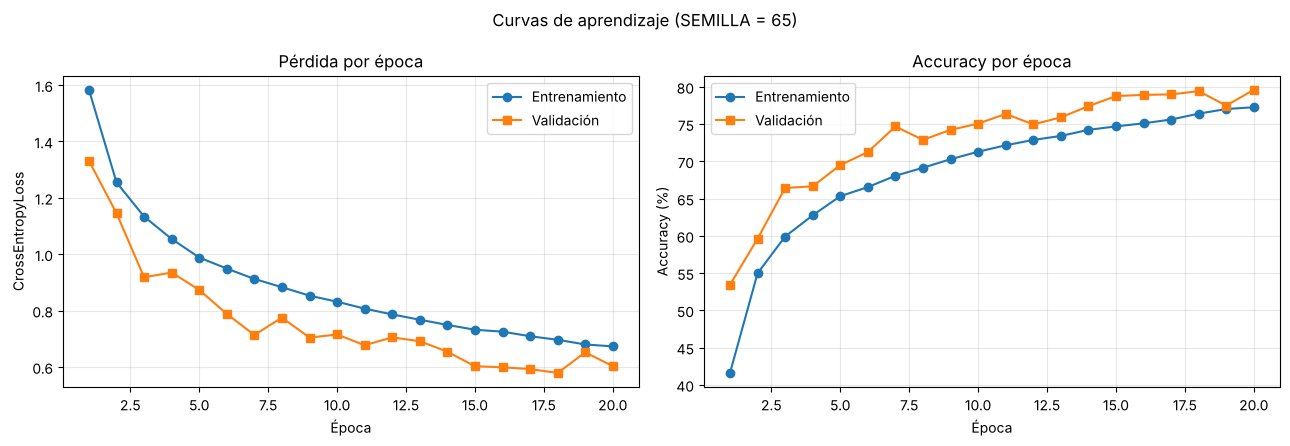

In [12]:
ep = hist["epoch"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(ep, hist["train_loss"], "o-", label="Entrenamiento"); ax1.plot(ep, hist["val_loss"], "s-", label="Validación")
ax1.set(title="Pérdida por época", xlabel="Época", ylabel="CrossEntropyLoss"); ax1.legend(); ax1.grid(alpha=.3)
ax2.plot(ep, [100*a for a in hist["train_acc"]], "o-", label="Entrenamiento")
ax2.plot(ep, [100*a for a in hist["val_acc"]], "s-", label="Validación")
ax2.set(title="Accuracy por época", xlabel="Época", ylabel="Accuracy (%)"); ax2.legend(); ax2.grid(alpha=.3)
plt.suptitle(f"Curvas de aprendizaje (SEMILLA = {SEMILLA})"); plt.tight_layout(); plt.show()

## 14. Evaluación sobre el conjunto de prueba

Se cargan los pesos del mejor modelo (elegido por accuracy de **validación**) y se evalúa una sola vez sobre las
10 000 imágenes de prueba, en modo `model.eval()` y sin gradientes.

In [13]:
model = CNNCifar10().to(device)
model.load_state_dict(torch.load(ckpt_path, map_location=device))
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, y_pred, y_true = evaluate(model, test_loader, criterion, device)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print(f"Test loss = {test_loss:.4f} | Test accuracy = {100*test_acc:.2f}%")
print(f"Precision macro = {p:.4f} | Recall macro = {r:.4f} | F1 macro = {f1:.4f}")
print("\n" + classification_report(y_true, y_pred, target_names=config.CLASSES, digits=4, zero_division=0))

Test loss = 0.6052 | Test accuracy = 79.26%
Precision macro = 0.8006 | Recall macro = 0.7926 | F1 macro = 0.7937

              precision    recall  f1-score   support

    airplane     0.8117    0.8190    0.8153      1000
  automobile     0.8752    0.9330    0.9032      1000
        bird     0.7754    0.6560    0.7107      1000
         cat     0.6103    0.6310    0.6205      1000
        deer     0.8273    0.7280    0.7745      1000
         dog     0.6312    0.8130    0.7107      1000
        frog     0.8368    0.8510    0.8438      1000
       horse     0.7836    0.8580    0.8191      1000
        ship     0.9285    0.8310    0.8770      1000
       truck     0.9264    0.8060    0.8620      1000

    accuracy                         0.7926     10000
   macro avg     0.8006    0.7926    0.7937     10000
weighted avg     0.8006    0.7926    0.7937     10000



## 15. Matriz de confusión y métricas

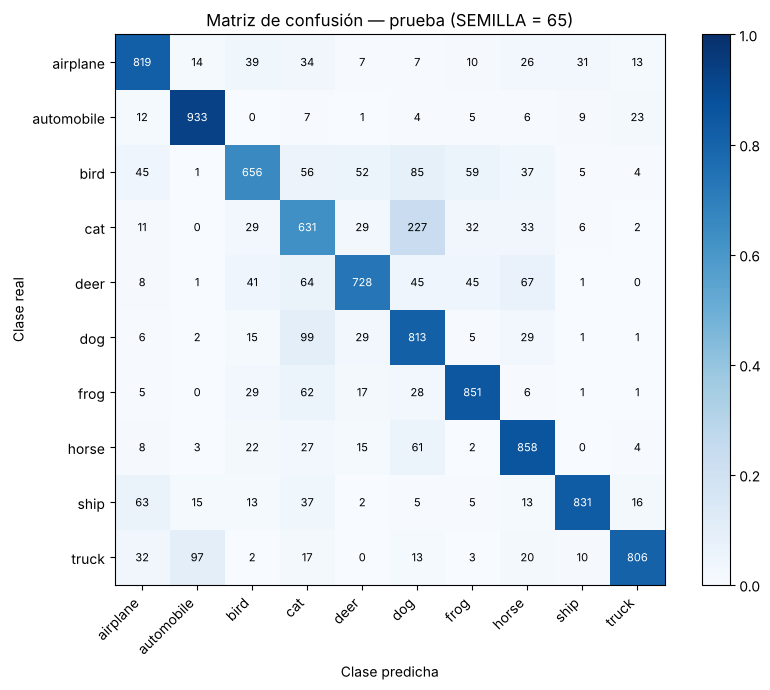

Confusiones más frecuentes (real -> predicha):
         cat -> dog        227 imágenes
         dog -> cat        99 imágenes
       truck -> automobile 97 imágenes
        bird -> dog        85 imágenes
        deer -> horse      67 imágenes


In [14]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(config.CLASSES, rotation=45, ha="right"); ax.set_yticklabels(config.CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm_norm[i, j] > .5 else "black")
ax.set(xlabel="Clase predicha", ylabel="Clase real", title=f"Matriz de confusión — prueba (SEMILLA = {SEMILLA})")
fig.colorbar(im, ax=ax, fraction=.046); plt.tight_layout(); plt.show()

# Principales confusiones (fuera de la diagonal)
off = [(cm[i, j], config.CLASSES[i], config.CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Confusiones más frecuentes (real -> predicha):")
for n, a, b in sorted(off, reverse=True)[:5]:
    print(f"  {a:>10} -> {b:<10} {n} imágenes")

## 16. Interpretación de los resultados

In [15]:
last = metrics["ultima_epoca"]
gap_acc = 100 * (last["train_accuracy"] - last["val_accuracy"])
gap_loss = last["val_loss"] - last["train_loss"]
print(f"Última época -> train acc {100*last['train_accuracy']:.2f}% | val acc {100*last['val_accuracy']:.2f}% | brecha {gap_acc:+.2f} pp")
print(f"Última época -> train loss {last['train_loss']:.4f} | val loss {last['val_loss']:.4f} | diferencia {gap_loss:+.4f}")
print(f"Validación (mejor) {100*metrics['mejor_val_accuracy']:.2f}% vs prueba {100*test_acc:.2f}%")
recall = {c: metrics['reporte_por_clase'][c]['recall'] for c in config.CLASSES}
print("Clase con mayor recall:", max(recall, key=recall.get), f"({recall[max(recall, key=recall.get)]:.3f})")
print("Clase con menor recall:", min(recall, key=recall.get), f"({recall[min(recall, key=recall.get)]:.3f})")

Última época -> train acc 77.26% | val acc 79.60% | brecha -2.34 pp
Última época -> train loss 0.6731 | val loss 0.6031 | diferencia -0.0700
Validación (mejor) 79.60% vs prueba 79.26%
Clase con mayor recall: automobile (0.933)
Clase con menor recall: cat (0.631)


**Interpretación (resultados reales de la ejecución con `SEMILLA = 65`, 20 épocas, Windows 11, CPU, CIFAR-10 oficial):**

- **Curvas de aprendizaje.** La pérdida de entrenamiento baja de forma monótona (1.5833 → 0.6731) y la de validación
  también desciende (1.3315 → 0.6031; mínimo 0.5788 en la época 18), con pequeñas oscilaciones (épocas 8, 12 y 19).
  No aparece el patrón típico de sobreajuste (validación que empeora mientras el entrenamiento mejora).
- **Validación por encima de entrenamiento.** En la época 20 la accuracy de validación (79.60 %) supera a la de
  entrenamiento (77.26 %). No es un error: la accuracy de entrenamiento se mide con *data augmentation* y con
  `Dropout` activo (`model.train()`), mientras que la validación usa imágenes sin alterar y el modelo completo
  (`model.eval()`).
- **Generalización.** La accuracy de prueba (79.26 %) es prácticamente igual a la de validación (79.60 %), por lo que
  la validación fue un estimador fiable del rendimiento sobre datos nuevos.
- **Diagnóstico.** No hay *overfitting*. Hay un **ligero underfitting / falta de convergencia**: ambas curvas
  seguían mejorando y la mejor época de validación fue justamente la 20; con más épocas o un *scheduler* de tasa de
  aprendizaje el modelo probablemente mejoraría.
- **Matriz de confusión.** La clase mejor reconocida es automobile (recall 0.933). Las más difíciles son **cat**
  (recall 0.631) y **bird** (0.656). La confusión dominante es *cat → dog* (227 imágenes), seguida de *dog → cat* (99),
  *truck → automobile* (97) y *bird → dog* (85): clases con formas, texturas o contexto parecidos a 32×32 píxeles.

## 17. Conclusiones

1. Se cargó CIFAR-10 con torchvision, se aplicó un pipeline con `ToTensor`, `Normalize` y aumento de datos
   (`RandomCrop`, `RandomHorizontalFlip`) y se realizó una partición estratificada 45 000 / 5 000 con `SEMILLA = 65`,
   conservando exactamente el 10 % de cada clase.
2. La CNN de tres bloques (Conv2d → BatchNorm2d → ReLU → MaxPool2d) y 620 810 parámetros procesa tensores 4D
   `(B, 3, 32, 32)` hasta `(B, 10)` sin *shape mismatch*, verificado con aserciones.
3. Con `CrossEntropyLoss` y `Adam` (lr = 0.001, 20 épocas) se obtuvo **79.26 % de accuracy en prueba**,
   precision macro 0.8006, recall macro 0.7926 y F1 macro 0.7937.
4. El modelo no muestra sobreajuste; muestra un leve subajuste (aún mejoraba al terminar). Las mayores dificultades
   están en distinguir animales similares, sobre todo gato/perro.
5. Mejoras posibles: más épocas, *learning-rate scheduler*, bloques convolucionales más profundos o más aumento de datos.